In [1]:
import numpy as np
import matplotlib.pyplot as plt


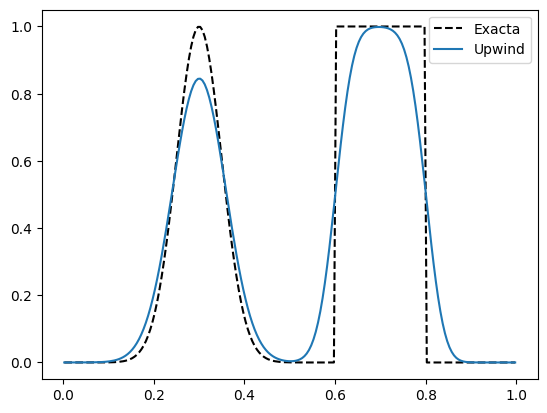

In [2]:
a, L, N, cfl = 1.0, 1.0, 200, 0.8
dx = L/N
x = (np.arange(N) + 0.5) * dx
dt = cfl * dx / a
nsteps = int(round(L / (a * dt)))
t_final = nsteps * dt

def u0(x):
  pulso_suave = np.exp(-200 * (x - 0.3)**2)
  pulso_cuadrado = np.where((x > 0.6) & (x < 0.8), 1.0, 0.0)
  return pulso_suave + pulso_cuadrado

def upwind(u, cfl):
  return u - cfl * (u - np.roll(u, 1))

def exacta(x, t):
  return u0((x - a * t) % L)

u = u0(x)
for _ in range (nsteps):
  u = upwind (u, cfl)

plt.plot(x, exacta(x, t_final), "k--", label="Exacta")
plt.plot(x, u, label="Upwind")
plt.legend()
plt.show()

Upwind: error L1 = 0.0707
Lax-Friedrichs: error L1 = 0.1141
Lax-Wendroff: error L1 = 0.0369


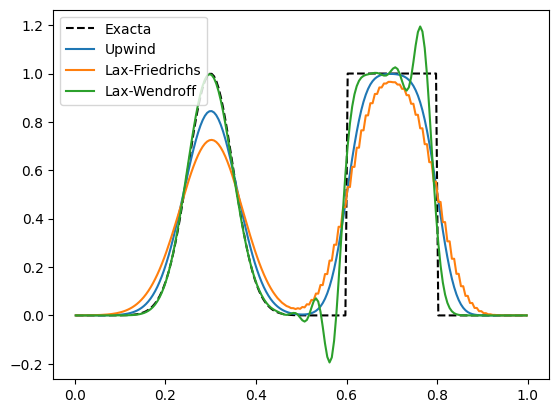

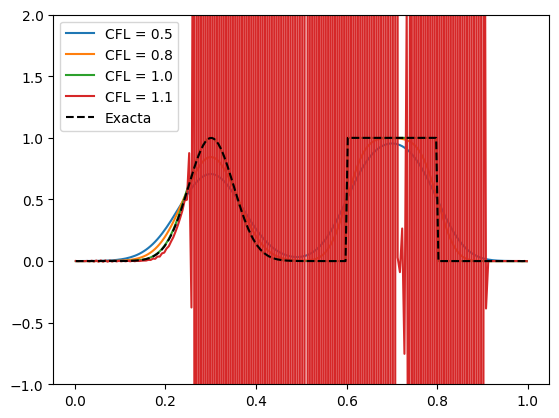

In [3]:
def lax_friedrichs(u, cfl):
    return 0.5 * (np.roll(u, -1) + np.roll(u, 1)) - 0.5 * cfl * (np.roll(u, -1) - np.roll(u, 1))

def lax_wendroff(u, cfl):
    return (u - 0.5 * cfl * (np.roll(u, -1) - np.roll(u, 1))
              + 0.5 * cfl**2 * (np.roll(u, -1) - 2 * u + np.roll(u, 1)))

def simular(esquema, f0, N=200, cfl=0.8):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    dt = cfl * dx / a
    nsteps = int(round(L / (a * dt)))
    t_final = nsteps * dt
    u = f0(x)
    for _ in range(nsteps):
        u = esquema(u, cfl)
    ue = f0((x - a * t_final) % L)
    error = np.sum(np.abs(u - ue)) * dx      # error L1
    return x, u, ue, error

esquemas = {"Upwind": upwind, "Lax-Friedrichs": lax_friedrichs, "Lax-Wendroff": lax_wendroff}

x, _, ue, _ = simular(upwind, u0)
plt.plot(x, ue, "k--", label="Exacta")
for nombre, esq in esquemas.items():
    x, u, ue, err = simular(esq, u0)
    print(f"{nombre}: error L1 = {err:.4f}")
    plt.plot(x, u, label=nombre)
plt.legend()
plt.show()

for c in [0.5, 0.8, 1.0, 1.1]:
    x, u, ue, err = simular(upwind, u0, cfl=c)
    plt.plot(x, u, label=f"CFL = {c}")
plt.plot(x, ue, "k--", label="Exacta")
plt.ylim(-1, 2)
plt.legend()
plt.show()

Upwind: orden observado = 0.87
Lax-Friedrichs: orden observado = 0.77
Lax-Wendroff: orden observado = 1.98


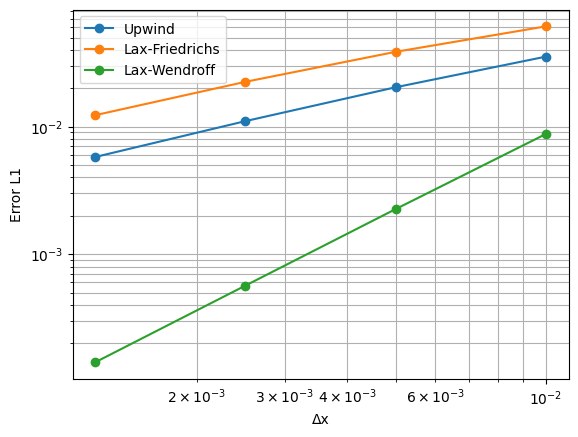

In [4]:
def u0_suave(x):
    return np.exp(-200 * (x - 0.3)**2)

Ns = [100, 200, 400, 800]
for nombre, esq in esquemas.items():
    errores = []
    for n in Ns:
        _, _, _, err = simular(esq, u0_suave, N=n)
        errores.append(err)
    dxs = [L / n for n in Ns]
    pendiente = np.polyfit(np.log(dxs), np.log(errores), 1)[0]
    print(f"{nombre}: orden observado = {pendiente:.2f}")
    plt.loglog(dxs, errores, "o-", label=nombre)

plt.xlabel("Δx"); plt.ylabel("Error L1")
plt.legend(); plt.grid(True, which="both")
plt.show()